# 01 · Dataset overview and data quality

**Question this notebook answers:** what is in `Dataset/Processed/`, how do the tables relate,
and can each table be trusted for a shipment delay-risk model?

Rules followed: source files are read-only; no rows are dropped; no values are imputed or
altered. The only transformations are type conversions (timestamp strings → UTC datetimes,
ordered categoricals), applied in `eda/src/cargomind_eda/io.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from cargomind_eda import io, lineage, plotting as P
from cargomind_eda.config import PROCESSED, RAW, EXPECTED_TABLES

P.setup()

## A1. Directory inventory
Verify which of the eight expected tables actually exist before analysing anything.

In [2]:
found, missing = io.available_tables()
inv = pd.DataFrame(
    {
        "file": [p.name for p in found.values()],
        "size_kb": [round(p.stat().st_size / 1024, 1) for p in found.values()],
        "expected": [n in EXPECTED_TABLES for n in found],
    },
    index=list(found),
)
print("Missing expected tables:", missing or "none")
print("Unexpected extra tables:", [n for n in found if n not in EXPECTED_TABLES] or "none")
inv

Missing expected tables: none
Unexpected extra tables: none


,file,size_kb,expected
disruption_events,disruption_events.csv,8.5,True
port_hourly_telemetry,port_hourly_telemetry.csv,"1,002",True
port_metadata,port_metadata.csv,1.1,True
port_network,port_network.csv,5.4,True
port_traffic_history,port_traffic_history.csv,34.4,True
public_holidays,public_holidays.csv,2.6,True
shipment_records,shipment_records.csv,"1,674",True
weather_hourly,weather_hourly.csv,"1,329",True


In [3]:
T = io.load_all()
S = {name: io.load_raw_strings(name) for name in T}  # string view, for format checks

## A2. Shape, dtypes, missingness and duplicates per table

In [4]:
def profile(name, df):
    return {
        "rows": len(df),
        "cols": df.shape[1],
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "cells_missing": int(df.isna().sum().sum()),
        "cols_with_missing": int((df.isna().sum() > 0).sum()),
        "memory_kb": round(df.memory_usage(deep=True).sum() / 1024, 1),
    }

pd.DataFrame({n: profile(n, d) for n, d in T.items()}).T

,rows,cols,exact_duplicate_rows,cells_missing,cols_with_missing,memory_kb
disruption_events,55,11,0,55,1,21.3
port_hourly_telemetry,1e+04,16,0,0,0,"2,677"
port_metadata,10,12,0,1,1,5.5
port_network,90,9,0,52,1,33.6
port_traffic_history,420,10,0,0,0,108
public_holidays,32,9,0,50,2,11.6
shipment_records,"9,850",16,0,0,0,"5,377"
weather_hourly,1e+04,15,0,0,0,"3,095"


In [5]:
miss = []
for n, d in T.items():
    for c in d.columns:
        k = d[c].isna().sum()
        if k:
            miss.append({"table": n, "column": c, "missing": k, "pct": round(100 * k / len(d), 1)})
pd.DataFrame(miss)

,table,column,missing,pct
0,disruption_events,source_url,55,100
1,port_metadata,subdivision_code,1,10
2,port_network,transshipment_port_id,52,57.8
3,public_holidays,subdivision_code,26,81.2
4,public_holidays,port_closed,24,75


Only four columns have missing values in the processed data and each one is **structurally**
missing rather than a gap in measurement:

* `port_network.transshipment_port_id` — blank for direct routes (verified below).
* `public_holidays.subdivision_code` — blank means a national holiday.
* `public_holidays.port_closed` — only populated for CN Spring Festival (`False`); unknown elsewhere.
* `port_metadata.subdivision_code` — Singapore is a city-state with no subdivision.
* `disruption_events.source_url` — entirely empty (no provenance link for any event).

None of these should be imputed. Section A7 shows, however, that "no missing values" in the
processed telemetry, weather and shipment tables is the result of filling during cleaning, not of
complete measurement.

In [6]:
for n, d in T.items():
    print(f"\n── {n}  {d.shape}")
    print(d.dtypes.astype(str).to_frame("dtype").T.to_string())


── disruption_events  (55, 11)
      event_id port_id          event_start            event_end event_type  severity affected_capacity_pct event_description source_url data_source is_synthetic
dtype   object  object  datetime64[ns, UTC]  datetime64[ns, UTC]     object  category               float64            object    float64      object         bool

── port_hourly_telemetry  (10000, 16)
      port_id              ts_hour throughput_teu port_utilization_pct container_dwell_hours vessel_time_in_port_hours vessel_arrivals vessel_departures vessels_at_anchor customs_hold_hours labour_status equipment_availability_pct customs_hold_is_synthetic labour_status_is_synthetic equipment_is_synthetic data_source
dtype  object  datetime64[ns, UTC]        float64              float64               float64                   float64           int64             int64             int64            float64        object                    float64                      bool                       bool   

## A3. Keys, granularity and referential integrity

In [7]:
keys = {
    "shipment_records": ["shipment_id"],
    "port_hourly_telemetry": ["port_id", "ts_hour"],
    "weather_hourly": ["port_id", "ts_hour"],
    "port_metadata": ["port_id"],
    "port_network": ["route_id"],
    "port_traffic_history": ["port_id", "period_start"],
    "disruption_events": ["event_id"],
    "public_holidays": ["country_code", "subdivision_code", "holiday_date"],
}
grain = {
    "shipment_records": "one row per shipment",
    "port_hourly_telemetry": "one row per port per UTC hour",
    "weather_hourly": "one row per port per UTC hour",
    "port_metadata": "one row per port",
    "port_network": "one row per directed origin→destination route",
    "port_traffic_history": "one row per port per UTC day",
    "disruption_events": "one row per event (interval at one port)",
    "public_holidays": "one row per country/subdivision per holiday date",
}
rows = []
for n, k in keys.items():
    d = T[n]
    rows.append({"table": n, "candidate_key": " + ".join(k), "key_unique": not d.duplicated(k).any(), "grain": grain[n]})
pd.DataFrame(rows).set_index("table")

,candidate_key,key_unique,grain
table,,,
shipment_records,shipment_id,True,one row per shipment
port_hourly_telemetry,port_id + ts_hour,True,one row per port per UTC hour
weather_hourly,port_id + ts_hour,True,one row per port per UTC hour
port_metadata,port_id,True,one row per port
port_network,route_id,True,one row per directed origin→destination route
port_traffic_history,port_id + period_start,True,one row per port per UTC day
disruption_events,event_id,True,one row per event (interval at one port)
public_holidays,country_code + subdivision_code + holiday_date,True,one row per country/subdivision per holiday date


In [8]:
ports = set(T["port_metadata"]["port_id"])
ship, net = T["shipment_records"], T["port_network"]
fk = {
    "shipment.origin_port_id ⊂ metadata": set(ship.origin_port_id) <= ports,
    "shipment.destination_port_id ⊂ metadata": set(ship.destination_port_id) <= ports,
    "shipment.route_id ⊂ network": set(ship.route_id) <= set(net.route_id),
    "shipment (origin,dest) matches its route": bool(
        ship.merge(net, on="route_id", suffixes=("", "_n")).eval("origin_port_id == origin_port_id_n and destination_port_id == destination_port_id_n").all()
    ),
    "network.transshipment_port_id ⊂ metadata": set(net.transshipment_port_id.dropna()) <= ports,
    "network: hub blank ⇔ route_type == direct": bool(((net.route_type == "direct") == net.transshipment_port_id.isna()).all()),
    "network: hub ≠ origin and ≠ destination": bool(((net.transshipment_port_id != net.origin_port_id) & (net.transshipment_port_id != net.destination_port_id) | net.transshipment_port_id.isna()).all()),
    "telemetry ports ⊂ metadata": set(T["port_hourly_telemetry"].port_id) <= ports,
    "weather ports ⊂ metadata": set(T["weather_hourly"].port_id) <= ports,
    "traffic ports ⊂ metadata": set(T["port_traffic_history"].port_id) <= ports,
    "disruption ports ⊂ metadata": set(T["disruption_events"].port_id) <= ports,
    "holiday countries ⊂ metadata countries": set(T["public_holidays"].country_code) <= set(T["port_metadata"].country_code),
    "holiday subdivisions ⊂ metadata subdivisions": set(T["public_holidays"].subdivision_code.dropna()) <= set(T["port_metadata"].subdivision_code.dropna()),
}
pd.Series(fk, name="holds").to_frame()

,holds
shipment.origin_port_id ⊂ metadata,True
shipment.destination_port_id ⊂ metadata,True
shipment.route_id ⊂ network,True
"shipment (origin,dest) matches its route",True
network.transshipment_port_id ⊂ metadata,True
network: hub blank ⇔ route_type == direct,True
network: hub ≠ origin and ≠ destination,True
telemetry ports ⊂ metadata,True
weather ports ⊂ metadata,True
traffic ports ⊂ metadata,True


In [9]:
# Network completeness: is every ordered port pair a route?
print("routes:", len(net), "| ordered port pairs:", len(ports) * (len(ports) - 1))
print("routes used by ≥1 shipment:", ship.route_id.nunique())
print(net.route_type.value_counts().to_dict(), "| hubs:", net.transshipment_port_id.value_counts().to_dict())

routes: 90 | ordered port pairs: 90
routes used by ≥1 shipment: 90
{'direct': 52, 'transshipment': 38} | hubs: {'SGSIN': 14, 'LKCMB': 9, 'MYPKG': 8, 'AEJEA': 7}


## A4. Timestamp formats and time coverage
Every timestamp column is checked as a raw string for one consistent format before parsing.

In [10]:
fmt_rows = []
iso_ts = re.compile(r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}\+00:00$")
iso_d = re.compile(r"^\d{4}-\d{2}-\d{2}$")
for n, cols in {**io.TS_COLUMNS, **io.DATE_COLUMNS}.items():
    for c in cols:
        s = S[n][c]
        pat = iso_d if n in io.DATE_COLUMNS else iso_ts
        fmt_rows.append({"table": n, "column": c, "pct_matching_ISO_UTC": round(100 * s.str.match(pat).mean(), 2),
                         "min": T[n][c].min(), "max": T[n][c].max()})
pd.DataFrame(fmt_rows)

,table,column,pct_matching_ISO_UTC,min,max
0,shipment_records,departure_ts,100,2025-01-02 00:00:00+00:00,2025-02-11 15:00:00+00:00
1,shipment_records,expected_arrival_ts,100,2025-01-03 02:00:00+00:00,2025-03-12 00:00:00+00:00
2,shipment_records,actual_arrival_ts,100,2025-01-03 02:30:00+00:00,2025-03-13 16:30:00+00:00
3,port_hourly_telemetry,ts_hour,100,2025-01-01 00:00:00+00:00,2025-02-11 15:00:00+00:00
4,weather_hourly,ts_hour,100,2025-01-01 00:00:00+00:00,2025-02-11 15:00:00+00:00
5,disruption_events,event_start,100,2025-01-01 12:00:00+00:00,2025-02-10 21:00:00+00:00
6,disruption_events,event_end,100,2025-01-02 11:00:00+00:00,2025-02-11 16:00:00+00:00
7,port_traffic_history,period_start,100,2025-01-01 00:00:00,2025-02-11 00:00:00
8,public_holidays,holiday_date,100,2025-01-01 00:00:00,2025-02-26 00:00:00


In [11]:
tel, wx = T["port_hourly_telemetry"], T["weather_hourly"]
for name, d in [("telemetry", tel), ("weather", wx)]:
    g = d.groupby("port_id")["ts_hour"]
    span = g.agg(["min", "max", "nunique"])
    span["expected_hours"] = ((span["max"] - span["min"]).dt.total_seconds() / 3600 + 1).astype(int)
    print(f"{name}: hourly grid complete for all ports →", bool((span["nunique"] == span["expected_hours"]).all()),
          "| hours per port:", span["nunique"].unique())
print("telemetry and weather share identical (port, hour) keys:",
      tel.set_index(["port_id", "ts_hour"]).index.equals(wx.set_index(["port_id", "ts_hour"]).index))
print("shipment departures minute≠0:", (ship.departure_ts.dt.minute != 0).sum(),
      "| actual arrivals minute≠0:", (ship.actual_arrival_ts.dt.minute != 0).sum())

telemetry: hourly grid complete for all ports → True | hours per port: [1000]
weather: hourly grid complete for all ports → True | hours per port: [1000]
telemetry and weather share identical (port, hour) keys: True
shipment departures minute≠0: 0 | actual arrivals minute≠0: 8880


share of shipments whose expected arrival is after the last telemetry hour: 27.4 %


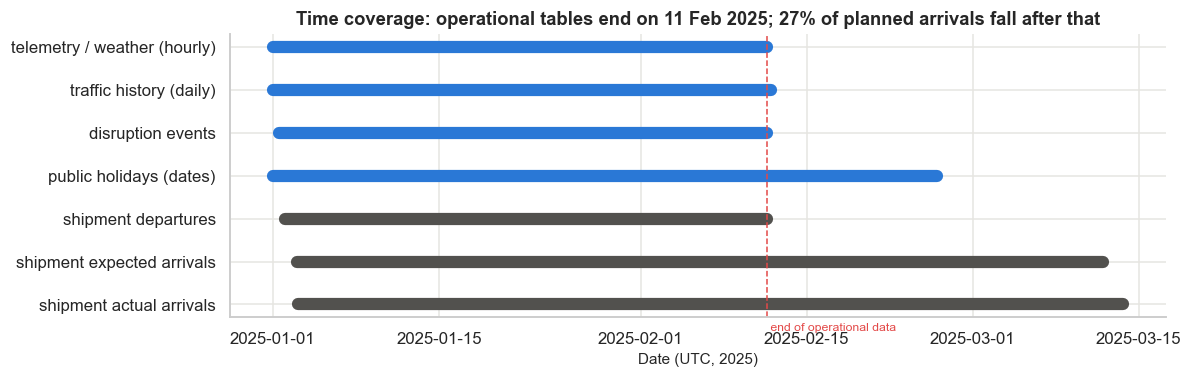

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.6))
spans = [
    ("telemetry / weather (hourly)", tel.ts_hour.min(), tel.ts_hour.max()),
    ("traffic history (daily)", T["port_traffic_history"].period_start.min().tz_localize("UTC"), T["port_traffic_history"].period_start.max().tz_localize("UTC") + pd.Timedelta("1D")),
    ("disruption events", T["disruption_events"].event_start.min(), T["disruption_events"].event_end.max()),
    ("public holidays (dates)", T["public_holidays"].holiday_date.min().tz_localize("UTC"), T["public_holidays"].holiday_date.max().tz_localize("UTC")),
    ("shipment departures", ship.departure_ts.min(), ship.departure_ts.max()),
    ("shipment expected arrivals", ship.expected_arrival_ts.min(), ship.expected_arrival_ts.max()),
    ("shipment actual arrivals", ship.actual_arrival_ts.min(), ship.actual_arrival_ts.max()),
]
for i, (lab, a, b) in enumerate(spans):
    ax.plot([a, b], [i, i], lw=8, solid_capstyle="round", color="#2a78d6" if "shipment" not in lab else "#52514e")
ax.axvline(tel.ts_hour.max(), color="#e34948", ls="--", lw=1)
ax.text(tel.ts_hour.max(), len(spans) - 0.4, " end of operational data", color="#e34948", fontsize=8)
ax.set_yticks(range(len(spans)), [s[0] for s in spans])
ax.invert_yaxis()
ax.set_xlabel("Date (UTC, 2025)")
ax.set_title("Time coverage: operational tables end on 11 Feb 2025; 27% of planned arrivals fall after that")
P.save(fig, "01_time_coverage")
print("share of shipments whose expected arrival is after the last telemetry hour:",
      round((ship.expected_arrival_ts > tel.ts_hour.max()).mean() * 100, 1), "%")

## A5. Numerical and categorical distributions (summary)
Per-table descriptive statistics. Detailed, target-focused distributions are in notebooks 02–07.

In [13]:
for n, d in T.items():
    num = d.select_dtypes("number")
    if num.shape[1]:
        print(f"\n── {n}")
        display(num.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)


── disruption_events


,count,mean,std,min,1%,25%,50%,75%,99%,max
affected_capacity_pct,55,53.79,20.97,16.87,17.53,36.88,51.95,72.52,85,85
source_url,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



── port_hourly_telemetry


,count,mean,std,min,1%,25%,50%,75%,99%,max
throughput_teu,1e+04,"1,397","1,302",51.6,123.7,649.8,900,"1,608","5,600","5,600"
port_utilization_pct,1e+04,75.9,17.32,9.06,26.01,65.58,75.72,88.81,100,100
container_dwell_hours,1e+04,89.72,22.73,54.6,61,71,84.7,105.1,177,205.2
vessel_time_in_port_hours,1e+04,25.31,5.185,18,18.5,21.5,24.1,27.9,42.2,60.4
vessel_arrivals,1e+04,3.093,3.263,0,0,1,2,4,14,23
vessel_departures,1e+04,2.947,3.152,0,0,1,2,4,13,22
vessels_at_anchor,1e+04,1.873,3.586,0,0,0,1,2,18,33
customs_hold_hours,1e+04,16.71,11.71,0.1,1.299,8,14.3,22.7,53.5,94.9
equipment_availability_pct,1e+04,92.48,4.443,57.6,65.3,91.2,93,94.6,98.7,100



── port_metadata


,count,mean,std,min,1%,25%,50%,75%,99%,max
latitude,10,23.87,18.84,1.264,1.421,8.483,21.98,33.11,53.4,53.54
longitude,10,51.07,70.72,-118.3,-107.2,21.25,76.4,96.12,119.9,121.5
capacity_teu_per_hour,10,"1,859","1,723",180,222.3,915,"1,300","1,700","5,483","5,600"


... (6 outputs left out)


── shipment_records


,count,mean,std,min,1%,25%,50%,75%,99%,max
container_teu,"9,850",11.94,8.415,1,1,6,10,16,39,60
actual_delay_hours,"9,850",18.35,29.45,-29.4,-15.3,-3.2,8.2,31.7,116.1,201



── weather_hourly


,count,mean,std,min,1%,25%,50%,75%,99%,max
grid_latitude,1e+04,23.88,17.88,1.25,1.25,7,22,33.75,53.5,53.5
grid_longitude,1e+04,51.08,67.08,-118.2,-118.2,10,76.38,101.5,121.5,121.5
temperature_2m_c,1e+04,17.71,10.46,-4.9,-2.2,7.2,21.8,26.4,32.1,34.6
relative_humidity_2m_pct,1e+04,69.56,7.58,41,54,65,69,74,91,100
precipitation_mm,1e+04,0.3132,1.479,0,0,0,0,0,7.901,30.1
wind_speed_10m_kmh,1e+04,17.66,8.691,0.5,4.9,12.5,16.3,20.4,53.5,66.2
wind_gusts_10m_kmh,1e+04,26.06,13.1,-0.2,6.4,18.2,24,30.5,80.3,105.7
wind_direction_10m_deg,1e+04,148.1,99.32,0,4,67,132,207,356,360
surface_pressure_hpa,1e+04,"1,012",4.029,985.5,994.3,"1,011","1,013","1,014","1,018","1,021"
visibility_m,1e+04,2.353e+04,"2,561",200,1.211e+04,2.27e+04,2.382e+04,2.488e+04,2.746e+04,3e+04


In [14]:
for n, d in T.items():
    cat = [c for c in d.columns if (d[c].dtype == object or str(d[c].dtype) in ("category", "bool")) and d[c].nunique() <= 15]
    for c in cat:
        vc = d[c].value_counts(dropna=False)
        print(f"{n}.{c}: {vc.to_dict()}")

disruption_events.port_id: {'MYPKG': 8, 'CNSHA': 7, 'INNSA': 7, 'NLRTM': 6, 'AEJEA': 6, 'LKCMB': 6, 'USLAX': 5, 'SGSIN': 5, 'DEHAM': 3, 'INMAA': 2}
disruption_events.event_type: {'weather': 27, 'equipment_failure': 11, 'congestion': 9, 'strike': 7, 'cyber': 1}
disruption_events.severity: {'high': 29, 'medium': 21, 'low': 5}
disruption_events.event_description: {'High winds suspended crane operations': 27, 'Quay crane / straddle carrier breakdown': 11, 'Yard congestion after vessel bunching': 9, "Dock workers' union strike; berth operations reduced": 7, 'Terminal operating system outage': 1}
disruption_events.data_source: {'synthetic': 55}
disruption_events.is_synthetic: {True: 55}
port_hourly_telemetry.port_id: {'INMAA': 1000, 'INNSA': 1000, 'SGSIN': 1000, 'CNSHA': 1000, 'AEJEA': 1000, 'NLRTM': 1000, 'USLAX': 1000, 'DEHAM': 1000, 'LKCMB': 1000, 'MYPKG': 1000}
port_hourly_telemetry.labour_status: {'normal': 8732, 'reduced': 897, 'strike': 371}
port_hourly_telemetry.customs_hold_is_synth

Constant columns (`data_source`, `is_synthetic`, `*_is_synthetic`) carry no information within this
dataset. They are metadata, and are excluded from features (notebook 09). Every row in every table
except `public_holidays` is flagged `is_synthetic = True` / `data_source = synthetic…` by the data itself;
conclusions in this EDA describe *this dataset* and are not claims about real ports or carriers.

## A6. Validity checks — invalid, inconsistent, and extreme-but-valid values

In [15]:
md = T["port_metadata"].set_index("port_id")
telc = tel.join(md["capacity_teu_per_hour"], on="port_id")
checks = [
    ("telemetry", "port_utilization_pct outside [0,100]", (~tel.port_utilization_pct.between(0, 100)).sum()),
    ("telemetry", "port_utilization_pct == 100 (saturated)", (tel.port_utilization_pct == 100).sum()),
    ("telemetry", "throughput_teu > capacity", (telc.throughput_teu > telc.capacity_teu_per_hour + 1e-9).sum()),
    ("telemetry", "throughput_teu < 0", (tel.throughput_teu < 0).sum()),
    ("telemetry", "equipment_availability_pct outside [0,100]", (~tel.equipment_availability_pct.between(0, 100)).sum()),
    ("telemetry", "negative counts (arrivals/departures/anchor)", (tel[["vessel_arrivals", "vessel_departures", "vessels_at_anchor"]] < 0).sum().sum()),
    ("telemetry", "customs_hold_hours <= 0", (tel.customs_hold_hours <= 0).sum()),
    ("weather", "relative_humidity outside [0,100]", (~wx.relative_humidity_2m_pct.between(0, 100)).sum()),
    ("weather", "relative_humidity == 100", (wx.relative_humidity_2m_pct == 100).sum()),
    ("weather", "precipitation_mm < 0", (wx.precipitation_mm < 0).sum()),
    ("weather", "wind_gusts < 0", (wx.wind_gusts_10m_kmh < 0).sum()),
    ("weather", "wind_gusts < wind_speed", (wx.wind_gusts_10m_kmh < wx.wind_speed_10m_kmh).sum()),
    ("weather", "wind_direction outside [0,360]", (~wx.wind_direction_10m_deg.between(0, 360)).sum()),
    ("weather", "visibility_m outside (0, 100000]", (~wx.visibility_m.between(1, 100000)).sum()),
    ("weather", "surface_pressure outside [950,1050] hPa", (~wx.surface_pressure_hpa.between(950, 1050)).sum()),
    ("shipment", "actual_arrival < departure", (ship.actual_arrival_ts < ship.departure_ts).sum()),
    ("shipment", "expected_arrival <= departure", (ship.expected_arrival_ts <= ship.departure_ts).sum()),
    ("shipment", "container_teu <= 0", (ship.container_teu <= 0).sum()),
    ("shipment", "container_teu non-integer", (ship.container_teu % 1 != 0).sum()),
    ("shipment", "delay ≠ actual − expected (|diff| > 0.05 h)", (((ship.actual_arrival_ts - ship.expected_arrival_ts).dt.total_seconds() / 3600 - ship.actual_delay_hours).abs() > 0.05).sum()),
    ("network", "route_distance_km <= 0", (net.route_distance_km <= 0).sum()),
    ("disruption", "event_end <= event_start", (T["disruption_events"].event_end <= T["disruption_events"].event_start).sum()),
    ("disruption", "affected_capacity_pct outside [0,100]", (~T["disruption_events"].affected_capacity_pct.between(0, 100)).sum()),
    ("traffic", "container_vessel_calls > vessel_calls", (T["port_traffic_history"].container_vessel_calls > T["port_traffic_history"].vessel_calls).sum()),
]
pd.DataFrame(checks, columns=["table", "check", "rows"])

,table,check,rows
0,telemetry,"port_utilization_pct outside [0,100]",0
1,telemetry,port_utilization_pct == 100 (saturated),1628
2,telemetry,throughput_teu > capacity,0
3,telemetry,throughput_teu < 0,0
4,telemetry,"equipment_availability_pct outside [0,100]",0
5,telemetry,negative counts (arrivals/departures/anchor),0
6,telemetry,customs_hold_hours <= 0,0
7,weather,"relative_humidity outside [0,100]",0
8,weather,relative_humidity == 100,6
9,weather,precipitation_mm < 0,0


**Interpretation of the non-zero checks**

* **Utilization = 100 % in 1,628 port-hours.** `port_utilization_pct` equals `throughput_teu / capacity_teu_per_hour × 100`
  (verified next cell), so 100 % means *throughput hit nominal capacity*. That is a valid saturated state (demand above
  capacity shows up as a growing anchor queue instead). It is a **censored** measurement: utilization cannot express how far
  demand exceeds capacity. Not an error; do not treat as outlier.
* **Wind gust < wind speed (77 h) and gust < 0 (2 h).** Physically a gust (peak) should not be below the mean wind. These are
  small-magnitude data-quality problems (likely residue of the swapped speed/gust columns noted in the raw issues log). They
  affect < 1 % of hours; flag, do not silently fix.
* **Humidity exactly 100 % (6 h)** is physically possible (fog/saturation); consistent with clipping of >100 % raw values. Valid.
* **Visibility 200 m** minima appear at almost every port — plausible in fog/heavy rain; investigated in notebook 05.

In [16]:
util_calc = telc.throughput_teu / telc.capacity_teu_per_hour * 100
print("max |utilization − throughput/capacity×100| =", round((util_calc - telc.port_utilization_pct).abs().max(), 3), "pp")
print("→ port_utilization_pct is a deterministic function of throughput_teu and port capacity (redundant).")
sat = tel.assign(sat=tel.port_utilization_pct == 100).groupby("port_id")["sat"].mean().mul(100).round(1)
print("\n% of hours at 100 % utilization by port:\n", sat.sort_values(ascending=False).to_string())

max |utilization − throughput/capacity×100| = 0.032 pp
→ port_utilization_pct is a deterministic function of throughput_teu and port capacity (redundant).

% of hours at 100 % utilization by port:
 port_id
NLRTM   40.9
USLAX   21.9
SGSIN   19.9
INNSA   19.7
CNSHA   19.2
LKCMB     19
DEHAM    9.3
AEJEA    6.6
INMAA    5.2
MYPKG    1.1


In [17]:
# Extreme-but-plausible values: how far do tails extend relative to the IQR?
def tail_report(d, cols):
    out = []
    for c in cols:
        x = d[c]
        q1, q3 = x.quantile([0.25, 0.75])
        hi = q3 + 3 * (q3 - q1)
        out.append({"column": c, "p99": x.quantile(0.99), "max": x.max(), "n_beyond_Q3+3IQR": int((x > hi).sum())})
    return pd.DataFrame(out).set_index("column")

display(tail_report(tel, ["container_dwell_hours", "vessel_time_in_port_hours", "vessels_at_anchor", "customs_hold_hours"]))
display(tail_report(wx, ["precipitation_mm", "wind_gusts_10m_kmh", "wind_speed_10m_kmh"]))
display(tail_report(ship, ["actual_delay_hours", "container_teu"]))

,p99,max,n_beyond_Q3+3IQR
column,,,
container_dwell_hours,177,205.2,0
vessel_time_in_port_hours,42.2,60.4,31
vessels_at_anchor,18,33,607
customs_hold_hours,53.5,94.9,32


,p99,max,n_beyond_Q3+3IQR
column,,,
precipitation_mm,7.901,30.1,975
wind_gusts_10m_kmh,80.3,105.7,259
wind_speed_10m_kmh,53.5,66.2,296


,p99,max,n_beyond_Q3+3IQR
column,,,
actual_delay_hours,116.1,201,35
container_teu,39,60,30


Extreme tails in dwell time, anchor queue and vessel time cluster in time at specific ports (notebook 04 shows they
coincide with disruption events), so they are treated as **valid extreme operating states**, not errors.
Heavy precipitation and gust tails are expected for weather data.

## A7. Lineage: what did cleaning fill in?

The processed tables contain no missing values in measurement columns and carry no imputation flags.
To distinguish observed values from values created during cleaning, the processed files are compared
(read-only) with `Dataset/Raw/`. A value is counted as *filled* when the raw cell was empty, a text
placeholder (`N/A`, `NaN`, `-`) or a numeric sentinel (`-999`, `-9999`, `9999`).

Note: this compares *cell presence*, not cell values. Values that were transformed (units, formats) are
not counted here.

In [18]:
lin = {}
for n in T:
    r = lineage.raw_vs_processed_summary(n)
    r = r[(r.raw_missing_or_placeholder + r.raw_numeric_sentinel) > 0]
    r = r.assign(table=n, raw_rows=r.attrs["raw_rows"], processed_rows=r.attrs["processed_rows"])
    lin[n] = r
lin_df = pd.concat(lin.values()).reset_index().set_index(["table", "column"])
lin_df

raw_missing_or_placeholder  raw_numeric_sentinel  processed_missing  raw_rows  processed_rows
table                 column                                                                                                                 
disruption_events     event_end                                          3                     0                  0        56              55
                      source_url                                        56                     0                 55        56              55
port_hourly_telemetry throughput_teu                                   200                     0                  0     10000           10000
                      container_dwell_hours                            293                    49                  0     10000           10000
                      vessel_arrivals                                   99                     0                  0     10000           10000
                      vessels_at_anchor                                200                     0                  0     10000           10000
                      customs_hold_hours                               500                     0                  0     10000           10000
                      labour_status                                    200                     0                  0     10000           10000
port_metadata         subdivision_code                                   1                     0                  1        11              10
                      capacity_teu_per_hour                              1                     0                  0        11              10
port_network          transshipment_port_id                             50                     0                 52        92              90
                      route_distance_km                                  4                     0                  0        92              90
port_traffic_history  import_volume_t                                   14                     0                  0       438             420
                      traffic_deviation_pct                             10                     0                  0       438             420
                      avg_vessel_stay_hours                             18                     0                  0       438             420
public_holidays       subdivision_code                                  23                     0                 26        33              32
                      port_closed                                       25                     0                 24        33              32
shipment_records      route_id                                         100                     0                  0     10000            9850
                      carrier                                          200                     0                  0     10000            9850
                      shipping_mode                                    100                     0                  0     10000            9850
                      cargo_type                                       300                     0                  0     10000            9850
                      container_teu                                    198                    30                  0     10000            9850
                      shipment_priority                                200                     0                  0     10000            9850
                      expected_arrival_ts                              199                     0                  0     10000            9850
                      actual_arrival_ts                                300                     0                  0     10000            9850
                      actual_delay_hours                               395                     0                  0     10000            9850
                      delay_status                                     3

In [19]:
flags = lineage.shipment_fill_flags()
fsum = flags.drop(columns="shipment_id").sum().rename("shipments").to_frame()
fsum["pct"] = (fsum.shipments / len(flags) * 100).round(2)
fsum

,shipments,pct
filled_route_id,100,1.02
filled_carrier,197,2
filled_shipping_mode,98,0.99
filled_cargo_type,295,2.99
filled_container_teu,225,2.28
filled_shipment_priority,195,1.98
filled_expected_arrival_ts,196,1.99
filled_actual_arrival_ts,295,2.99
filled_actual_delay_hours,389,3.95
filled_delay_status,295,2.99


In [20]:
flags.to_csv(ROOT / "data" / "interim" / "shipment_lineage_flags.csv", index=False)
print("saved eda/data/interim/shipment_lineage_flags.csv")
any_feat = flags[[c for c in flags if c.startswith("filled_") and c not in ("filled_actual_arrival_ts", "filled_actual_delay_hours", "filled_delay_status")]].any(axis=1)
print("shipments with ≥1 filled input attribute:", any_feat.sum(), f"({any_feat.mean()*100:.1f}%)")

saved eda/data/interim/shipment_lineage_flags.csv
shipments with ≥1 filled input attribute: 1231 (12.5%)


In [21]:
# Which ports had visibility entirely missing in raw?
raw_wx = pd.read_csv(RAW / "weather_hourly.csv", dtype=str, keep_default_na=False)
raw_wx["port_norm"] = raw_wx.port_id.str.strip().str.upper()
vis_missing = raw_wx.assign(m=raw_wx.visibility_m.str.strip().isin(lineage.TEXT_PLACEHOLDERS)).groupby("port_norm")["m"].agg(["sum", "size"])
vis_missing = vis_missing[vis_missing["sum"] > 0].sort_values("sum", ascending=False)
vis_missing.head(8)

,sum,size
port_norm,,
USLAX,993,993
CNSHA,991,991
LKCMB,986,986
COLOMBO,10,10
SHANGHAI,7,7
LOS ANGELES,6,6
CNSAH,4,4
USLA,1,1


### Lineage findings (important for modelling)

1. **295 shipments (3.0 %) had no observed outcome in the raw data** — `actual_arrival_ts`, `actual_delay_hours` and
   `delay_status` were all empty — yet the processed file contains values for all three. The method used to produce
   these targets cannot be determined from the data. They are not observed labels and should be **excluded from model
   training and evaluation** (or at minimum flagged and tested in a sensitivity analysis). Notebook 02 compares their
   distribution to the observed rows.
2. **97 shipments carried the ambiguous raw label `Late`**; the processed label was recomputed from timestamps and 58 of
   them are now `On-Time`. Recomputation from timestamps is consistent with the stated thresholds, but it shows the raw
   label channel was unreliable.
3. **Shipment input attributes were filled** for ~1–3 % of rows each (carrier, cargo type, priority, TEU, mode, route,
   expected arrival); **1,231 shipments (12.5 %) have at least one filled input attribute**. Route can be derived exactly
   from origin/destination, but filled carrier/cargo/priority/TEU values are not observations. The flags are saved to
   `eda/data/interim/shipment_lineage_flags.csv` for sensitivity checks.
4. **Telemetry**: ≈ 1,540 cells across throughput, dwell, arrivals, anchor queue, customs hold and labour status were empty or
   sentinels in raw and are populated in processed (raw also lacked 120 whole port-hours). The largest is
   `customs_hold_hours` (500 cells). Weather similarly had gusts (150) and humidity (100) gaps filled. These cannot be
   located in the processed file without a row-level raw↔processed join, so treat telemetry as ~2–5 % reconstructed.
5. **Weather visibility was entirely absent in raw for USLAX, CNSHA and LKCMB** (≈ 3,000 port-hours). The processed values for
   those three ports are therefore not measurements. Visibility features are unreliable for these ports.
6. Three disruption events had no end time in raw; their processed end times are reconstructed.

## A8. Role of each table in the delay-risk problem

| Table | Grain | Role | Join to shipment |
|---|---|---|---|
| `shipment_records` | shipment | **Fact table**: target (`delay_status`), outcome (`actual_*`), static shipment attributes | — |
| `port_network` | route | Static route attributes: distance, planned hours, direct vs transshipment, hub | `route_id` (m:1) |
| `port_metadata` | port | Static port attributes: capacity, region, country/subdivision, timezone | origin / destination / hub `port_id` (m:1) |
| `port_hourly_telemetry` | port × hour | Time-varying port congestion and operations | (`port_id`, hour ≤ prediction cutoff) per port role |
| `weather_hourly` | port × hour | Time-varying weather at each port | same as telemetry |
| `disruption_events` | event interval | Strikes, weather, congestion, equipment, cyber events | interval overlap with cutoff, per port role |
| `port_traffic_history` | port × day | Daily vessel calls, volumes, deviation from normal | last complete day before departure |
| `public_holidays` | country/subdivision × date | Calendar, known in advance | via port country/subdivision, near departure / expected arrival |

Detailed join logic, temporal matching and duplication checks: notebook 08.